# Eksplorasi Python untuk Distribusi Probabilitas
**Mata kuliah:** Statistika dan Probabilitas — Politeknik Caltex Riau

Notebook ini disusun mengikuti **modul 05 Distribusi Probabilitas Variabel Random** (daftar distribusi diskrit: Hipergeometrik, proses Bernoulli [Binomial, Geometrik, Binomial Negatif], proses Poisson [Poisson, Eksponensial]; kontinu: Normal). Soal berkode berakhiran **0** (HIP0, BIN0, BIN0B, POI0, NOR0, NOR0B) adalah **contoh yang diambil dari modul**, sehingga angkanya dapat dicocokkan langsung dengan slide. Soal DES1 dan DES2 menghubungkan distribusi dengan **statistika deskriptif** (lembar perkuliahan Pertemuan 4).
Soal lainnya dibuat dengan bantuan AI (Claude), lalu diperiksa. Pada setiap soal, baris `Cek vs manual` membandingkan hasil Python dengan angka yang dihitung tangan pada bagian *Hitungan manual*. Untuk simulasi hasilnya hanya mendekati, jadi dipakai toleransi yang tertulis pada label pembandingnya.

| Kode | Distribusi | Jenis | Contoh konteks Teknik Informatika |
|---|---|---|---|
| HIP | Hipergeometrik | Diskrit | sampling modul berisi bug |
| BIN | Binomial (dan Bernoulli) | Diskrit | paket data gagal, tebakan benar |
| POI | Poisson | Diskrit | request per menit, bug per modul |
| GEO | Geometrik | Diskrit | percobaan login hingga berhasil |
| NBI | Binomial Negatif | Diskrit | upload sampai sukses ke-r |
| NOR | Normal | Kontinu | nilai ujian, waktu respons |
| EKS | Eksponensial | Kontinu | selang antar request, umur komponen |

**Fungsi `scipy.stats`:** `pmf` / `pdf` (peluang di satu titik / kepadatan), `cdf` (P(X ≤ x)), `sf` (P(X > x)), `ppf` (kuantil), `mean()`, `var()`, `std()`, `stats(moments='mvsk')`, `rvs(size=n)` (simulasi).

**Padanan fungsi Excel pada modul ↔ Python:**

| Excel (modul) | Python |
|---|---|
| `FACT(n)`, `PERMUT(n,r)`, `COMBIN(n,r)` | `math.factorial(n)`, `math.perm(n,r)`, `math.comb(n,r)` |
| `BINOM.DIST(x,n,p,FALSE/TRUE)` | `stats.binom.pmf(x,n,p)` / `stats.binom.cdf(x,n,p)` |
| `HYPGEOM.DIST(x,n,k,N,FALSE/TRUE)` | `stats.hypergeom.pmf(x,N,k,n)` / `.cdf(x,N,k,n)` (urutan argumen berbeda) |
| `POISSON.DIST(x,λ,FALSE/TRUE)` | `stats.poisson.pmf(x,λ)` / `.cdf(x,λ)` |
| `NORM.DIST(x,μ,σ,FALSE/TRUE)` | `stats.norm.pdf(x,μ,σ)` / `.cdf(x,μ,σ)` |
| `NORM.INV(p,μ,σ)` | `stats.norm.ppf(p,μ,σ)` |
| `NORM.S.DIST(z,TRUE/FALSE)` | `stats.norm.cdf(z)` / `.pdf(z)` |
| `NORM.S.INV(p)` | `stats.norm.ppf(p)` |

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (6, 3.5), "axes.grid": True, "grid.alpha": 0.3})

def cocok(manual, python, tol=1e-4):
    return "SAMA" if abs(float(manual) - float(python)) < tol else "BERBEDA"
print("Siap. scipy", __import__("scipy").__version__)

Siap. scipy 1.16.3


---
## Distribusi 1 — Binomial (diskrit)
X = jumlah sukses dalam **n percobaan independen**, tiap percobaan sukses dengan peluang p.
P(X = k) = C(n,k) pᵏ (1−p)ⁿ⁻ᵏ  |  E[X] = np  |  Var(X) = np(1−p)
Fungsi: `stats.binom.pmf(k, n, p)`, `.cdf`, `.sf`, `.ppf`, `.rvs`; kasus n = 1: `stats.bernoulli`.

#### Soal BIN0 — Kegiatan A mendapat dana 3 kali dalam 5 tahun (contoh modul)

**Soal:** Setiap tahun, selama 5 tahun, dipilih acak satu dari 4 kegiatan (A, B, C, D) untuk didanai. Berapa peluang kegiatan A mendapat dana tepat 3 kali? Buat tabel peluang untuk 0 sampai 5 kali, serta E(X) dan Var(X).

**Hitungan manual:**

p = 1/4 = 0,25; q = 0,75; n = 5.
f(3; 5, 0,25) = C(5,3) (0,25)³ (0,75)² = 10 × 0,015625 × 0,5625 = 0,0879
f(0) = 0,2373; f(1) = 0,3955; f(2) = 0,2637; f(3) = 0,0879; f(4) = 0,0146; f(5) = 0,0010 (jumlah = 1)
E(X) = np = 1,25; Var(X) = npq = 0,9375

 Jumlah sukses  Jumlah cara  Probabilitas  Kumulatif F(x)
             0            1        0.2373          0.2373
             1            5        0.3955          0.6328
             2           10        0.2637          0.8965
             3           10        0.0879          0.9844
             4            5        0.0146          0.9990
             5            1        0.0010          1.0000
f(3) = 0.0879 | jumlah probabilitas = 1.0000 | E(X) = 1.25 | Var(X) = 0.9375


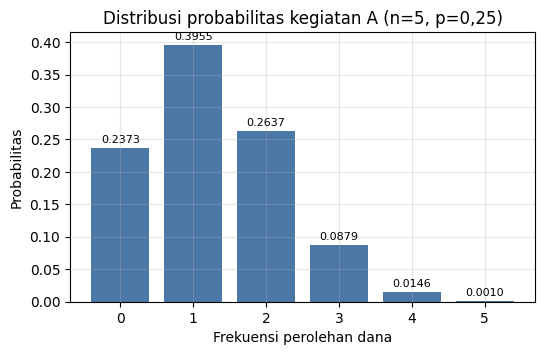

Cek vs manual (f(3)): SAMA
Cek vs manual (f(0)): SAMA
Cek vs manual (jumlah probabilitas): SAMA
Cek vs manual (E(X)): SAMA
Cek vs manual (Var(X)): SAMA


In [ ]:
n, p = 5, 0.25
x = np.arange(0, n + 1)
pmf = stats.binom.pmf(x, n, p)                         # Excel: BINOM.DIST(x, n, p, FALSE)
tabel = pd.DataFrame({"Jumlah sukses": x, "Jumlah cara": [math.comb(n, i) for i in x],
                      "Probabilitas": pmf.round(4), "Kumulatif F(x)": stats.binom.cdf(x, n, p).round(4)})
print(tabel.to_string(index=False))
bin0_f3, bin0_f0 = pmf[3], pmf[0]
bin0_jumlah = pmf.sum()
bin0_mean, bin0_var = stats.binom.mean(n, p), stats.binom.var(n, p)
print(f"f(3) = {bin0_f3:.4f} | jumlah probabilitas = {bin0_jumlah:.4f} | E(X) = {bin0_mean} | Var(X) = {bin0_var}")

plt.bar(x, pmf, color="#4C78A8")
for xi, pi in zip(x, pmf):
    plt.text(xi, pi + 0.008, f"{pi:.4f}", ha="center", fontsize=8)
plt.xlabel("Frekuensi perolehan dana"); plt.ylabel("Probabilitas"); plt.title("Distribusi probabilitas kegiatan A (n=5, p=0,25)")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (f(3)):", cocok(0.0879, bin0_f3, 0.0001))
print("Cek vs manual (f(0)):", cocok(0.2373, bin0_f0, 0.0001))
print("Cek vs manual (jumlah probabilitas):", cocok(1, bin0_jumlah, 1e-09))
print("Cek vs manual (E(X)):", cocok(1.25, bin0_mean, 1e-09))
print("Cek vs manual (Var(X)):", cocok(0.9375, bin0_var, 1e-09))

**Interpretasi BIN0:** Peluang kegiatan A mendapat dana tepat 3 kali adalah 0,0879 (sekitar 8,8%). Kejadian yang paling mungkin adalah A mendapat dana 1 kali (39,6%), dan tidak mendapat dana sama sekali pun cukup mungkin (23,7%). Rata-rata 1,25 kali, sama dengan 5 × 1/4, dan jumlah seluruh peluang = 1. Hasil ini sama dengan tabel pada modul.

#### Soal BIN0B — Skewness binomial dan mendekati kurva normal (contoh modul)

**Soal:** Untuk p = 0,25, hitung koefisien skewness cs = (q − p)/√(npq) untuk n = 5, 10, 20, 50, bandingkan dengan nilai dari `scipy`, dan gambarkan histogram binomial dengan kurva normal N(np, npq). Tafsirkan memakai acuan skewness dari lembar perkuliahan.

**Hitungan manual:**

n = 5: cs = (0,75 − 0,25)/√(5×0,25×0,75) = 0,5/0,9682 = 0,5164
n = 50: cs = 0,5/√9,375 = 0,1633
Makin besar n, cs mendekati 0 dan bentuk histogram mendekati lonceng (kurva normal).
Catatan: slide modul menyebut q > p sebagai 'negative skew', padahal rumus cs = (q − p)/√(npq) bernilai positif saat q > p, artinya ekor panjang berada di kanan (positive skew). Notebook ini mengikuti tanda cs.

n =  5: cs rumus = 0.5164 | scipy = 0.5164 -> cukup dekat simetris, positif (ekor kanan)
n = 10: cs rumus = 0.3651 | scipy = 0.3651 -> sangat mendekati simetris, positif (ekor kanan)
n = 20: cs rumus = 0.2582 | scipy = 0.2582 -> sangat mendekati simetris, positif (ekor kanan)
n = 50: cs rumus = 0.1633 | scipy = 0.1633 -> sangat mendekati simetris, positif (ekor kanan)


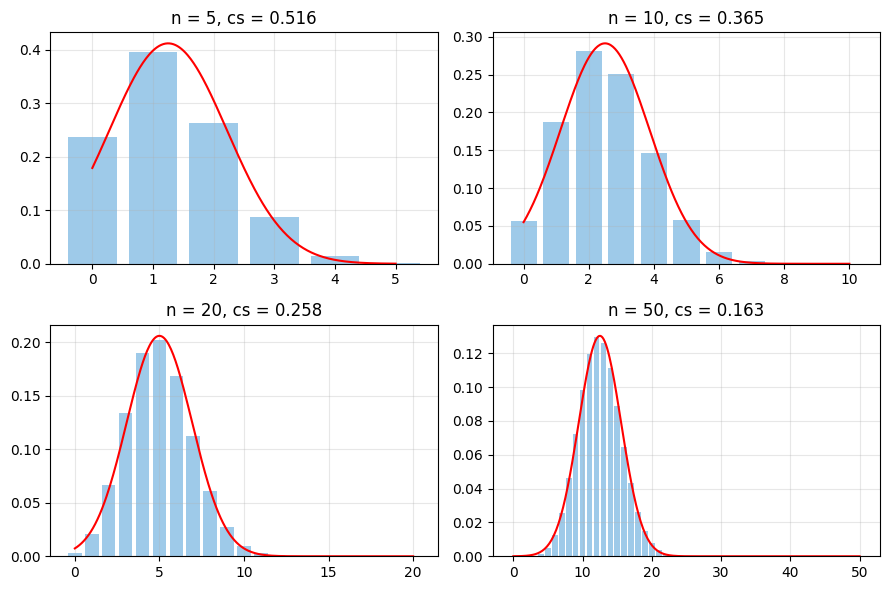

Cek vs manual (cs n=5): SAMA
Cek vs manual (cs n=50): SAMA


In [ ]:
p, q = 0.25, 0.75

def tafsir(cs):
    a = abs(cs)
    arah = "positif (ekor kanan)" if cs > 0 else "negatif (ekor kiri)" if cs < 0 else "simetris"
    if a <= 0.5: kat = "sangat mendekati simetris"
    elif a <= 1: kat = "cukup dekat simetris"
    elif a <= 2: kat = "masih dapat ditoleransi"
    else: kat = "kemencengan kuat"
    return f"{kat}, {arah}"

fig, ax = plt.subplots(2, 2, figsize=(9, 6))
for a, n in zip(ax.ravel(), (5, 10, 20, 50)):
    cs_rumus = (q - p) / math.sqrt(n * p * q)
    cs_scipy = float(stats.binom.stats(n, p, moments="s"))
    print(f"n = {n:2d}: cs rumus = {cs_rumus:.4f} | scipy = {cs_scipy:.4f} -> {tafsir(cs_rumus)}")
    xs = np.arange(0, n + 1)
    a.bar(xs, stats.binom.pmf(xs, n, p), color="#9ecae9")
    xx = np.linspace(0, n, 300)
    a.plot(xx, stats.norm.pdf(xx, n * p, math.sqrt(n * p * q)), "r")
    a.set_title(f"n = {n}, cs = {cs_rumus:.3f}")
plt.tight_layout(); plt.show()
bin0b_cs5 = float(stats.binom.stats(5, p, moments="s"))
bin0b_cs50 = float(stats.binom.stats(50, p, moments="s"))

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (cs n=5):", cocok(0.5/math.sqrt(0.9375), bin0b_cs5, 1e-06))
print("Cek vs manual (cs n=50):", cocok(0.5/math.sqrt(9.375), bin0b_cs50, 1e-06))

**Interpretasi BIN0B:** Skewness untuk n = 5 adalah 0,5164 (positif, di atas 0,5: mencong ke kanan karena p kecil), turun menjadi 0,1633 pada n = 50 yang sudah sangat mendekati simetris menurut acuan ±0,5. Kurva normal (merah) makin tepat menutupi histogram saat n bertambah, sehingga distribusi binomial dapat didekati dengan distribusi normal untuk n besar.

#### Soal BIN1 — Tepat 2 paket gagal

**Soal:** Sebuah pesan dikirim dalam 10 paket. Tiap paket gagal terkirim dengan peluang 0,1 (independen). Berapa peluang tepat 2 paket gagal? Gambarkan distribusi lengkapnya.

**Hitungan manual:**

X ~ Bin(10; 0,1). P(X=2) = C(10,2)(0,1)²(0,9)⁸ = 45 × 0,01 × 0,43047 = 0,19371

P(X=2) = 0.19371
Manual vs Python: SAMA


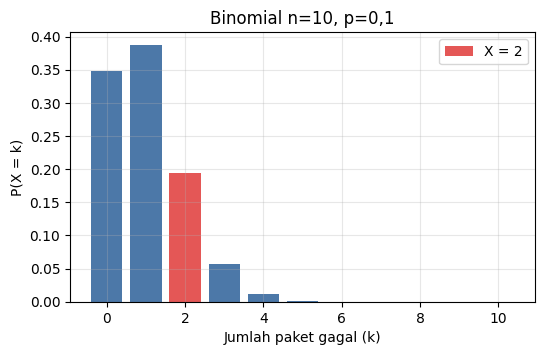

In [ ]:
n, p = 10, 0.1
bin1_p = stats.binom.pmf(2, n, p)
print(f"P(X=2) = {bin1_p:.5f}")
print("Manual vs Python:", cocok(0.19371, bin1_p, 1e-5))

k = np.arange(0, n + 1)
plt.bar(k, stats.binom.pmf(k, n, p), color="#4C78A8")
plt.bar(2, bin1_p, color="#E45756", label="X = 2")
plt.xlabel("Jumlah paket gagal (k)"); plt.ylabel("P(X = k)"); plt.title("Binomial n=10, p=0,1"); plt.legend()
plt.show()

**Interpretasi BIN1:** Peluang tepat 2 paket gagal adalah 0,1937 (≈ 19,4%). Grafik menunjukkan distribusi condong ke kanan dengan nilai paling mungkin 0 atau 1 paket gagal; kejadian 2 gagal masih cukup umum, sedangkan lebih dari 4 gagal hampir tidak pernah terjadi.

#### Soal BIN2 — Paling banyak 1 paket gagal (cdf)

**Soal:** Dari soal BIN1, berapa peluang paling banyak 1 paket gagal?

**Hitungan manual:**

P(X ≤ 1) = P(0) + P(1) = 0,9¹⁰ + 10(0,1)(0,9)⁹ = 0,34868 + 0,38742 = 0,73610

In [ ]:
bin2_cdf = stats.binom.cdf(1, 10, 0.1)
bin2_jumlah = stats.binom.pmf(0, 10, 0.1) + stats.binom.pmf(1, 10, 0.1)
print(f"P(X <= 1) via cdf   = {bin2_cdf:.5f}")
print(f"P(0) + P(1)         = {bin2_jumlah:.5f}")
print("Manual vs Python:", cocok(0.73610, bin2_cdf, 1e-5))

P(X <= 1) via cdf   = 0.73610
P(0) + P(1)         = 0.73610
Manual vs Python: SAMA


**Interpretasi BIN2:** Peluang paling banyak 1 paket gagal adalah 0,7361 (73,6%). Fungsi `cdf` memberi hasil yang sama dengan menjumlahkan `pmf` secara manual. Artinya sekitar 26,4% pesan mengalami 2 kegagalan atau lebih.

---
## Distribusi 2 — Poisson (diskrit)
X = jumlah kejadian dalam suatu interval waktu/ruang, dengan laju rata-rata λ.
P(X = k) = e⁻λ λᵏ / k!  |  E[X] = Var(X) = λ
Fungsi: `stats.poisson.pmf(k, mu)`, `.cdf`, `.sf`, `.ppf`, `.rvs`.

#### Soal POI0 — Salah cetak printer (contoh modul)

**Soal:** Sebuah printer membuat kesalahan acak rata-rata 2 kesalahan per halaman. Hitung peluang tepat satu salah cetak dalam satu halaman, peluang paling banyak 2 kesalahan, serta koefisien skewness.

**Hitungan manual:**

λ = 2, x = 1: f(1; 2) = 2¹ e⁻² / 1! = 2/e² = 0,2707
F(2) = e⁻²(1 + 2 + 2) = 5e⁻² = 0,6767
Skewness cs = λ^(−1/2) = 1/√2 = 0,7071

f(1; 2) = 0.2707 | F(2) = 0.6767 | skewness = 0.7071 (rumus 1/sqrt(lambda) = 0.7071)
 x   f(x)   F(x)
 0 0.1353 0.1353
 1 0.2707 0.4060
 2 0.2707 0.6767
 3 0.1804 0.8571
 4 0.0902 0.9473
 5 0.0361 0.9834
 6 0.0120 0.9955
 7 0.0034 0.9989
 8 0.0009 0.9998


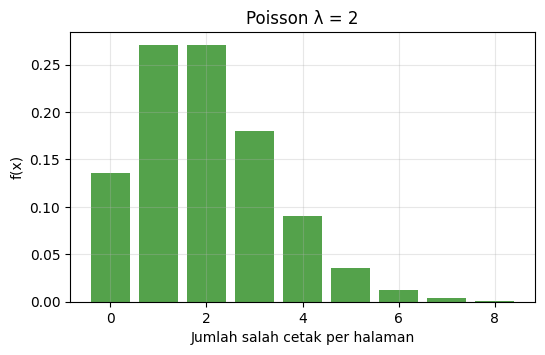

Cek vs manual (f(1;2)): SAMA
Cek vs manual (F(2)): SAMA
Cek vs manual (skewness): SAMA


In [ ]:
lam = 2
poi0_p1 = stats.poisson.pmf(1, lam)               # Excel: POISSON.DIST(1, 2, FALSE)
poi0_cdf2 = stats.poisson.cdf(2, lam)
poi0_skew = float(stats.poisson.stats(lam, moments="s"))
print(f"f(1; 2) = {poi0_p1:.4f} | F(2) = {poi0_cdf2:.4f} | skewness = {poi0_skew:.4f} (rumus 1/sqrt(lambda) = {1/math.sqrt(lam):.4f})")
k = np.arange(0, 9)
print(pd.DataFrame({"x": k, "f(x)": stats.poisson.pmf(k, lam).round(4), "F(x)": stats.poisson.cdf(k, lam).round(4)}).to_string(index=False))
plt.bar(k, stats.poisson.pmf(k, lam), color="#54A24B")
plt.xlabel("Jumlah salah cetak per halaman"); plt.ylabel("f(x)"); plt.title("Poisson λ = 2")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (f(1;2)):", cocok(0.2707, poi0_p1, 0.0001))
print("Cek vs manual (F(2)):", cocok(5*math.exp(-2), poi0_cdf2, 1e-09))
print("Cek vs manual (skewness):", cocok(1/math.sqrt(2), poi0_skew, 1e-09))

**Interpretasi POI0:** Peluang tepat satu salah cetak per halaman adalah 0,2707 (sekitar 27,1%), setara dengan nilai pada modul. Peluang paling banyak 2 salah cetak 67,7%. Skewness 0,7071 (positif), yaitu distribusi miring ke kanan karena λ kecil; menurut acuan lembar perkuliahan nilai ini berada pada interval ±1 sehingga masih cukup dekat dengan simetris.

#### Soal POI1 — Tepat 6 request per menit

**Soal:** Sebuah server menerima rata-rata 4 request per menit (Poisson). Berapa peluang tepat 6 request dalam satu menit?

**Hitungan manual:**

λ = 4. P(X=6) = e⁻⁴ 4⁶ / 6! = 0,018316 × 4096 / 720 = 0,10420

scipy = 0.10420 | rumus langsung = 0.10420
Manual vs Python: SAMA


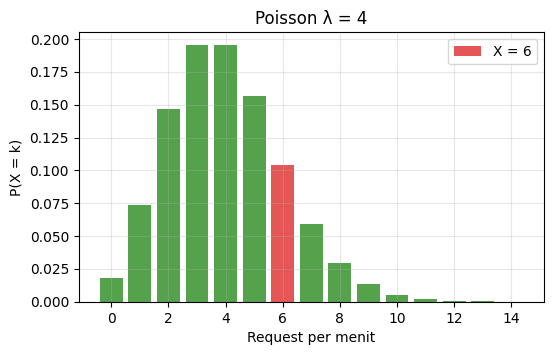

In [ ]:
lam = 4
poi1_p = stats.poisson.pmf(6, lam)
poi1_rumus = math.exp(-lam) * lam**6 / math.factorial(6)
print(f"scipy = {poi1_p:.5f} | rumus langsung = {poi1_rumus:.5f}")
print("Manual vs Python:", cocok(0.10420, poi1_p, 1e-5))

k = np.arange(0, 15)
plt.bar(k, stats.poisson.pmf(k, lam), color="#54A24B")
plt.bar(6, poi1_p, color="#E45756", label="X = 6")
plt.xlabel("Request per menit"); plt.ylabel("P(X = k)"); plt.legend(); plt.title("Poisson λ = 4")
plt.show()

**Interpretasi POI1:** Peluang tepat 6 request per menit adalah 0,1042 (≈ 10,4%). Nilai paling mungkin berada di sekitar λ = 4 (3 dan 4 request), dan peluangnya mengecil bila k menjauhi rata-rata.

#### Soal POI2 — Paling banyak 2 request

**Soal:** Pada server yang sama (λ = 4 per menit), berapa peluang paling banyak 2 request dalam satu menit?

**Hitungan manual:**

P(X ≤ 2) = e⁻⁴(1 + 4 + 8) = 13 e⁻⁴ = 0,2381

In [ ]:
poi2_p = stats.poisson.cdf(2, 4)
print(f"P(X <= 2) = {poi2_p:.5f}")
print("Manual vs Python:", cocok(13 * math.exp(-4), poi2_p, 1e-8))

P(X <= 2) = 0.23810
Manual vs Python: SAMA


**Interpretasi POI2:** Peluang paling banyak 2 request per menit adalah 0,2381 (23,8%), jadi dalam sekitar 1 dari 4 menit server relatif sepi. Hasil `cdf` identik dengan rumus manual 13e⁻⁴.

#### Soal POI3 — Minimal 1 request dalam 30 detik (penskalaan λ)

**Soal:** Dengan laju 4 request per menit, berapa peluang minimal 1 request datang dalam 30 detik?

**Hitungan manual:**

Dalam 30 detik λ = 4 × 0,5 = 2. P(X ≥ 1) = 1 − P(0) = 1 − e⁻² = 0,8647

In [ ]:
lam30 = 4 * 0.5
poi3_p = stats.poisson.sf(0, lam30)       # P(X >= 1)
print(f"lambda 30 detik = {lam30}")
print(f"P(X >= 1) = {poi3_p:.5f}")
print("Manual vs Python:", cocok(1 - math.exp(-2), poi3_p, 1e-8))

lambda 30 detik = 2.0
P(X >= 1) = 0.86466
Manual vs Python: SAMA


**Interpretasi POI3:** Parameter λ harus disesuaikan dengan panjang interval. Untuk 30 detik λ menjadi 2, sehingga peluang minimal satu request ≈ 86,5%. Server hampir selalu menerima setidaknya satu request tiap setengah menit.

#### Soal POI7 — Menentukan kapasitas server

**Soal:** Rata-rata 5 request/menit. Server memproses maksimal 8 request/menit. (a) Berapa peluang server kelebihan beban (> 8)? (b) Berapa kapasitas minimum per menit agar peluang kelebihan beban < 1%?

**Hitungan manual:**

(a) P(X > 8) = 1 − P(X ≤ 8) ≈ 0,0681
(b) Cari k terkecil dengan P(X > k) < 0,01 → P(X > 10) = 0,0137 (masih lebih besar), P(X > 11) = 0,0055 → k = 11.

(a) P(X > 8) = 0.0681
(b) Kapasitas minimum = 11 request/menit (P overload = 0.0055)
Cek dengan ppf: 11


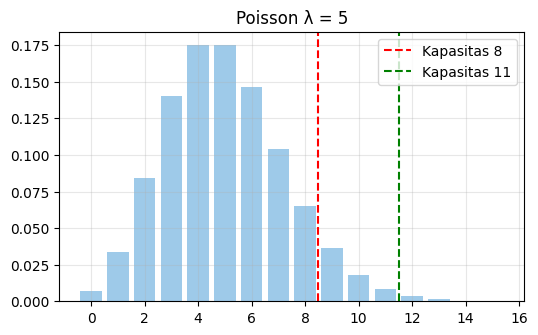

Cek vs manual (P(X>8)): SAMA
Cek vs manual (kapasitas, toleransi 0.5): SAMA


In [ ]:
lam = 5
poi7_a = stats.poisson.sf(8, lam)
k = 0
while stats.poisson.sf(k, lam) >= 0.01:
    k += 1
poi7_k = k
print(f"(a) P(X > 8) = {poi7_a:.4f}")
print(f"(b) Kapasitas minimum = {poi7_k} request/menit (P overload = {stats.poisson.sf(poi7_k, lam):.4f})")
print("Cek dengan ppf:", int(stats.poisson.ppf(0.99, lam)))

kk = np.arange(0, 16)
plt.bar(kk, stats.poisson.pmf(kk, lam), color="#9ecae9")
plt.axvline(8.5, color="red", ls="--", label="Kapasitas 8")
plt.axvline(poi7_k + 0.5, color="green", ls="--", label=f"Kapasitas {poi7_k}")
plt.legend(); plt.title("Poisson λ = 5"); plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(X>8)):", cocok(0.0681, poi7_a, 0.0001))
print("Cek vs manual (kapasitas, toleransi 0.5):", cocok(11, poi7_k, 0.5))

**Interpretasi POI7:** Dengan kapasitas 8, server kelebihan beban 6,8% dari waktu. Agar risiko di bawah 1% dibutuhkan kapasitas minimal 11 request/menit, bukan sekadar sedikit di atas rata-rata 5. Contoh penerapan distribusi untuk perencanaan kapasitas (capacity planning).

---
## Distribusi 3 — Geometrik (diskrit)
X = nomor percobaan **pertama yang sukses** (X = 1, 2, 3, …), peluang sukses tiap percobaan p.
P(X = k) = (1−p)ᵏ⁻¹ p  |  E[X] = 1/p  |  Var(X) = (1−p)/p²  |  P(X > k) = (1−p)ᵏ
Fungsi: `stats.geom.pmf(k, p)`, `.cdf`, `.sf`, `.rvs`.

#### Soal GEO1 — Login berhasil pada percobaan ke-3

**Soal:** Seorang penyerang menebak password, tiap tebakan benar dengan peluang 0,2. Berapa peluang tebakan benar pertama terjadi pada percobaan ke-3?

**Hitungan manual:**

P(X=3) = (0,8)² × 0,2 = 0,64 × 0,2 = 0,128

P(X=3) = 0.1280
Manual vs Python: SAMA


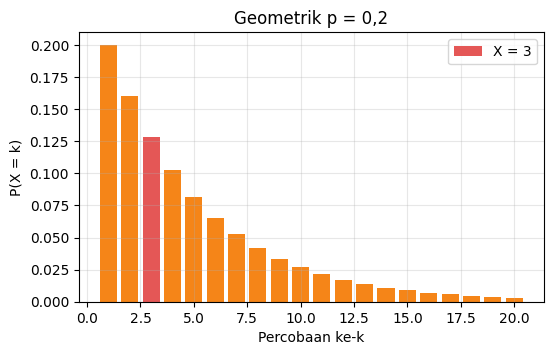

In [ ]:
p = 0.2
geo1_p = stats.geom.pmf(3, p)
print(f"P(X=3) = {geo1_p:.4f}")
print("Manual vs Python:", cocok(0.128, geo1_p, 1e-9))

k = np.arange(1, 21)
plt.bar(k, stats.geom.pmf(k, p), color="#F58518")
plt.bar(3, geo1_p, color="#E45756", label="X = 3")
plt.xlabel("Percobaan ke-k"); plt.ylabel("P(X = k)"); plt.legend(); plt.title("Geometrik p = 0,2")
plt.show()

**Interpretasi GEO1:** Peluangnya 0,128 (12,8%). Grafik menurun monoton: percobaan pertama selalu yang paling mungkin menjadi saat sukses (p = 0,2), kemudian peluangnya berkurang secara geometris.

#### Soal GEO2 — Berhasil dalam 5 percobaan

**Soal:** Dengan p = 0,2, berapa peluang berhasil paling lambat pada percobaan ke-5?

**Hitungan manual:**

P(X ≤ 5) = 1 − (0,8)⁵ = 1 − 0,32768 = 0,67232

In [ ]:
geo2_p = stats.geom.cdf(5, 0.2)
print(f"P(X <= 5) = {geo2_p:.5f}")
print("Manual vs Python:", cocok(1 - 0.8**5, geo2_p, 1e-9))

P(X <= 5) = 0.67232
Manual vs Python: SAMA


**Interpretasi GEO2:** Peluang sukses dalam 5 percobaan pertama adalah 0,672 (67,2%). Meski peluang sukses tiap percobaan kecil, kumulatif peluang dalam beberapa percobaan menjadi besar; ini mengapa sistem perlu membatasi jumlah percobaan login.

#### Soal GEO7 — Simulasi Geometrik

**Soal:** Bangkitkan 100.000 sampel X ~ Geom(0,25), bandingkan mean dan varians dengan teori, dan gambarkan histogram terhadap pmf.

**Hitungan manual:**

E[X] = 1/0,25 = 4; Var = 0,75/0,0625 = 12

Simulasi: mean = 4.010, var = 12.023
Teori   : mean = 4.0, var = 12.0


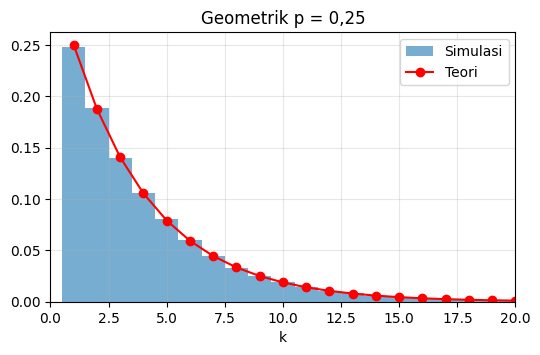

Cek vs manual (mean, toleransi 0.1): SAMA
Cek vs manual (var, toleransi 0.5): SAMA


In [ ]:
p = 0.25
data = stats.geom.rvs(p, size=100_000, random_state=5)
geo7_mean, geo7_var = data.mean(), data.var()
print(f"Simulasi: mean = {geo7_mean:.3f}, var = {geo7_var:.3f}")
print(f"Teori   : mean = {1/p}, var = {(1-p)/p**2}")

k = np.arange(1, 21)
plt.hist(data, bins=np.arange(0.5, 21.5), density=True, alpha=0.6, label="Simulasi")
plt.plot(k, stats.geom.pmf(k, p), "ro-", label="Teori")
plt.xlim(0, 20); plt.legend(); plt.xlabel("k"); plt.title("Geometrik p = 0,25")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (mean, toleransi 0.1):", cocok(4, geo7_mean, 0.1))
print("Cek vs manual (var, toleransi 0.5):", cocok(12, geo7_var, 0.5))

**Interpretasi GEO7:** Mean simulasi 4,01 dan varians 12,02 mendekati teori (4 dan 12). Histogram mengikuti kurva pmf yang menurun, menegaskan bahwa distribusi geometrik condong ke kanan dengan ekor panjang.

---
## Distribusi 4 — Hipergeometrik (diskrit)
Pengambilan **tanpa pengembalian** (notasi modul): populasi berukuran N berisi k elemen 'sukses' dan N−k 'gagal'; diambil sampel berukuran n.
f(x; N, n, k) = C(k,x) C(N−k, n−x) / C(N,n)  |  E[X] = nk/N  |  Var(X) = nk(N−k)(N−n) / (N²(N−1))
Fungsi: `stats.hypergeom.pmf(x, N, k, n)`. Di Excel: `HYPGEOM.DIST(x, n, k, N, FALSE)` — **urutan argumennya berbeda**, hati-hati saat memindahkan rumus.

#### Soal HIP0 — Stasiun penakar hujan rusak (contoh modul)

**Soal:** Suatu DAS memiliki N = 12 stasiun penakar hujan dan k = 2 di antaranya rusak. Dipilih n = 6 stasiun secara acak. Berapa peluang terpilih stasiun rusak sejumlah x = 2, 1, atau 0? Hitung juga E(X) dan Var(X).

**Hitungan manual:**

f(x; N, n, k) = C(k,x) C(N−k, n−x) / C(N,n), dengan C(12,6) = 924.
f(2) = C(2,2) C(10,4)/924 = 210/924 = 0,2273
f(1) = C(2,1) C(10,5)/924 = 504/924 = 0,5454
f(0) = C(2,0) C(10,6)/924 = 210/924 = 0,2273
E(X) = nk/N = 6×2/12 = 1
Var(X) = n k (N−k)(N−n) / (N² (N−1)) = 6×2×10×6 / (144×11) = 720/1584 = 0,4545

 x   f(x)   F(x)  rumus kombinasi
 0 0.2273 0.2273           0.2273
 1 0.5455 0.7727           0.5455
 2 0.2273 1.0000           0.2273
E(X) = 1.0000 (rumus nk/N = 1.0000) | Var(X) = 0.4545 (rumus = 0.4545)


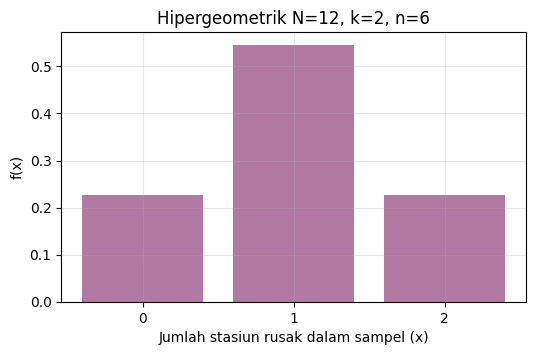

Cek vs manual (f(2)): SAMA
Cek vs manual (f(1)): SAMA
Cek vs manual (f(0)): SAMA
Cek vs manual (E(X)): SAMA
Cek vs manual (Var(X)): SAMA


In [ ]:
N, k, n = 12, 2, 6                       # notasi modul: populasi N, sukses k, sampel n
x = np.arange(0, 3)
pmf = stats.hypergeom.pmf(x, N, k, n)    # Excel: HYPGEOM.DIST(x, n, k, N, FALSE)  (urutan argumen berbeda!)
cdf = stats.hypergeom.cdf(x, N, k, n)    # Excel: HYPGEOM.DIST(x, n, k, N, TRUE)
tabel = pd.DataFrame({"x": x, "f(x)": pmf, "F(x)": cdf,
                      "rumus kombinasi": [math.comb(k, i) * math.comb(N - k, n - i) / math.comb(N, n) for i in x]})
print(tabel.round(4).to_string(index=False))
hip0_f2, hip0_f1, hip0_f0 = pmf[2], pmf[1], pmf[0]
hip0_e = (x * pmf).sum()                                   # E(X) = jumlah x f(x)
hip0_e_rumus = n * k / N
hip0_var = stats.hypergeom.var(N, k, n)
hip0_var_rumus = n * k * (N - k) * (N - n) / (N**2 * (N - 1))
print(f"E(X) = {hip0_e:.4f} (rumus nk/N = {hip0_e_rumus:.4f}) | Var(X) = {hip0_var:.4f} (rumus = {hip0_var_rumus:.4f})")

plt.bar(x, pmf, color="#B279A2")
plt.xticks(x); plt.xlabel("Jumlah stasiun rusak dalam sampel (x)"); plt.ylabel("f(x)")
plt.title("Hipergeometrik N=12, k=2, n=6")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (f(2)):", cocok(0.2273, hip0_f2, 0.0001))
print("Cek vs manual (f(1)):", cocok(0.5454, hip0_f1, 0.0001))
print("Cek vs manual (f(0)):", cocok(0.2273, hip0_f0, 0.0001))
print("Cek vs manual (E(X)):", cocok(1, hip0_e, 1e-09))
print("Cek vs manual (Var(X)):", cocok(720/1584, hip0_var, 1e-09))

**Interpretasi HIP0:** Peluang sampel berisi 0, 1, dan 2 stasiun rusak adalah 0,2273, 0,5455, dan 0,2273; jumlahnya 1 (slide modul menulis 0,5454 karena dipotong, nilai tepatnya 0,54545). Nilai paling mungkin adalah tepat 1 stasiun rusak (sekitar 54,5%). Ekspektasi 1 stasiun rusak, sama dengan nk/N, dan varians 0,4545. Catatan: pada slide modul, rumus varians tertulis (N−n)(N−n); yang benar (N−k)(N−n), dan hasil 0,4545 di atas memakai rumus yang benar.

#### Soal HIP1 — Tepat 1 modul berbug dalam sampel

**Soal:** Dari 50 modul, 8 modul mengandung bug. Diambil 5 modul acak untuk diuji. Berapa peluang tepat 1 modul berbug?

**Hitungan manual:**

P(X=1) = C(8,1) C(42,4) / C(50,5) = 8 × 111.930 / 2.118.760 = 0,42262

scipy = 0.42262 | rumus kombinasi = 0.42262
Manual vs Python: SAMA


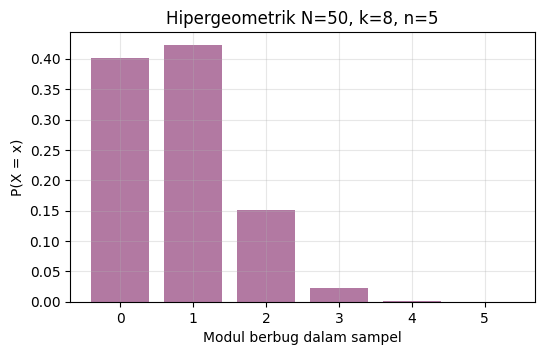

In [ ]:
N, k, n = 50, 8, 5            # populasi N, sukses k, sampel n (notasi modul)
hip1_p = stats.hypergeom.pmf(1, N, k, n)
hip1_cek = math.comb(8, 1) * math.comb(42, 4) / math.comb(50, 5)
print(f"scipy = {hip1_p:.5f} | rumus kombinasi = {hip1_cek:.5f}")
print("Manual vs Python:", cocok(0.42262, hip1_p, 1e-5))

x = np.arange(0, 6)
plt.bar(x, stats.hypergeom.pmf(x, N, k, n), color="#B279A2")
plt.xlabel("Modul berbug dalam sampel"); plt.ylabel("P(X = x)"); plt.title("Hipergeometrik N=50, k=8, n=5")
plt.show()

**Interpretasi HIP1:** Peluang sampel berisi tepat satu modul berbug adalah 0,4226 (≈ 42,3%), nilai tertinggi pada distribusi. Rumus kombinasi manual dan `scipy` memberi angka yang sama.

#### Soal HIP2 — Sampel lolos tanpa mendeteksi bug

**Soal:** Pada kasus HIP1, berapa peluang sampel tidak berisi modul berbug sama sekali (bug tak terdeteksi), dan berapa peluang minimal satu bug terdeteksi?

**Hitungan manual:**

P(X=0) = C(42,5)/C(50,5) = 850.668 / 2.118.760 = 0,40149
P(X ≥ 1) = 1 − 0,40149 = 0,59851

In [ ]:
hip2_0 = stats.hypergeom.pmf(0, 50, 8, 5)
hip2_min1 = stats.hypergeom.sf(0, 50, 8, 5)
print(f"P(X=0)  = {hip2_0:.5f}")
print(f"P(X>=1) = {hip2_min1:.5f}")
print("Manual vs Python:", cocok(0.40149, hip2_0, 1e-5), cocok(0.59851, hip2_min1, 1e-5))

P(X=0)  = 0.40149
P(X>=1) = 0.59851
Manual vs Python: SAMA SAMA


**Interpretasi HIP2:** Ada 40,1% peluang pengujian 5 modul tidak menemukan bug, meskipun 16% modul berbug. Peluang menemukan setidaknya satu bug hanya 59,9%, jadi ukuran sampel perlu diperbesar bila ingin deteksi andal.

---
## Distribusi 5 — Binomial Negatif (diskrit)
Termasuk proses Bernoulli pada daftar distribusi modul (bersama Binomial dan Geometrik). X = nomor percobaan **tempat sukses ke-r terjadi** (X = r, r+1, r+2, …).
f(x; r, p) = C(x−1, r−1) pʳ qˣ⁻ʳ  |  E[X] = r/p  |  Var(X) = r(1−p)/p²  |  untuk r = 1 menjadi distribusi Geometrik.
Fungsi: `stats.nbinom.pmf(x − r, r, p)`. **Perhatian:** `scipy` menghitung jumlah *kegagalan* sebelum sukses ke-r, sehingga banyaknya percobaan = kegagalan + r. Itulah mengapa argumen pertama dikurangi r.

#### Soal NBI1 — Sukses ke-3 pada percobaan ke-5

**Soal:** Setiap upload file berhasil dengan peluang 0,6 (independen). Berapa peluang upload sukses ke-3 terjadi tepat pada upload ke-5?

**Hitungan manual:**

f(5; 3, 0,6) = C(4,2) (0,6)³ (0,4)² = 6 × 0,216 × 0,16 = 0,20736

scipy = 0.20736 | rumus = 0.20736


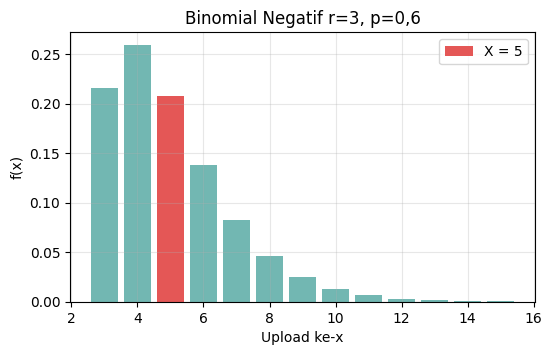

Cek vs manual (f(5;3,0.6)): SAMA


In [ ]:
r, p = 3, 0.6
nbi1_p = stats.nbinom.pmf(5 - r, r, p)
nbi1_rumus = math.comb(4, 2) * p**3 * (1 - p) ** 2
print(f"scipy = {nbi1_p:.5f} | rumus = {nbi1_rumus:.5f}")
x = np.arange(r, 16)
plt.bar(x, stats.nbinom.pmf(x - r, r, p), color="#72B7B2")
plt.bar(5, nbi1_p, color="#E45756", label="X = 5")
plt.xlabel("Upload ke-x"); plt.ylabel("f(x)"); plt.legend(); plt.title("Binomial Negatif r=3, p=0,6")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (f(5;3,0.6)):", cocok(6*0.216*0.16, nbi1_p, 1e-09))

**Interpretasi NBI1:** Peluangnya 0,2074 (≈ 20,7%). Sukses ke-3 paling cepat terjadi pada percobaan ke-3, dan percobaan yang paling mungkin adalah ke-4 (sekitar 25,9%) menurut grafik. Hasil `scipy` sama dengan rumus kombinasi.

#### Soal NBI2 — Selesai dalam 6 upload

**Soal:** Dengan r = 3 dan p = 0,6, berapa peluang sukses ke-3 sudah tercapai paling lambat pada upload ke-6?

**Hitungan manual:**

P(X ≤ 6) = f(3) + f(4) + f(5) + f(6) = 0,2160 + 0,2592 + 0,2074 + 0,1382 = 0,8208

In [ ]:
r, p = 3, 0.6
nbi2_p = stats.nbinom.cdf(6 - r, r, p)
nbi2_jumlah = sum(stats.nbinom.pmf(x - r, r, p) for x in range(3, 7))
print(f"P(X <= 6) via cdf = {nbi2_p:.4f} | jumlah pmf = {nbi2_jumlah:.4f}")

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(X<=6)):", cocok(0.8208, nbi2_p, 0.0001))

P(X <= 6) via cdf = 0.8208 | jumlah pmf = 0.8208
Cek vs manual (P(X<=6)): SAMA


**Interpretasi NBI2:** Peluang tiga upload sukses sudah tercapai dalam 6 percobaan adalah 0,8208 (82,1%). Sisanya sekitar 17,9% memerlukan lebih dari 6 percobaan.

#### Soal NBI7 — Simulasi Binomial Negatif

**Soal:** Bangkitkan 100.000 sampel jumlah percobaan sampai sukses ke-3 (p = 0,6), lalu bandingkan mean, varians, dan histogramnya dengan teori.

**Hitungan manual:**

E[X] = 5; Var(X) = 3,3333

Simulasi: mean = 5.011, var = 3.365
Teori   : mean = 5.000, var = 3.333


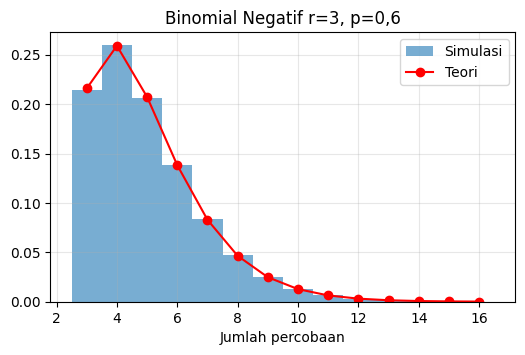

Cek vs manual (mean, toleransi 0.05): SAMA
Cek vs manual (var, toleransi 0.1): SAMA


In [ ]:
r, p = 3, 0.6
data = rng.negative_binomial(r, p, 100_000) + r      # numpy menghitung jumlah gagal; tambah r = jumlah percobaan
nbi7_mean, nbi7_var = data.mean(), data.var()
print(f"Simulasi: mean = {nbi7_mean:.3f}, var = {nbi7_var:.3f}")
print(f"Teori   : mean = 5.000, var = {r*(1-p)/p**2:.3f}")
x = np.arange(r, 17)
plt.hist(data, bins=np.arange(r - 0.5, 17.5), density=True, alpha=0.6, label="Simulasi")
plt.plot(x, stats.nbinom.pmf(x - r, r, p), "ro-", label="Teori")
plt.legend(); plt.xlabel("Jumlah percobaan"); plt.title("Binomial Negatif r=3, p=0,6")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (mean, toleransi 0.05):", cocok(5, nbi7_mean, 0.05))
print("Cek vs manual (var, toleransi 0.1):", cocok(10/3, nbi7_var, 0.1))

**Interpretasi NBI7:** Mean simulasi 5,011 dan varians 3,365 mendekati nilai teori 5 dan 3,333. Histogram menempel pada pmf, sehingga cara menghitung jumlah gagal lalu menambah r sudah benar.

---
## Distribusi 6 — Normal (kontinu)
X ~ N(μ, σ²). Standardisasi: Z = (X − μ)/σ ~ N(0,1).
Aturan empiris: ±1σ ≈ 68,27%, ±2σ ≈ 95,45%, ±3σ ≈ 99,73%.
Fungsi: `stats.norm.pdf(x, loc=μ, scale=σ)`, `.cdf`, `.sf`, `.ppf`, `.rvs`.

#### Soal NOR0 — Distribusi normal N(12, 3²) (contoh modul)

**Soal:** Variabel X berdistribusi normal dengan rerata 12 dan simpangan baku 3. Hitung prob(X < 15), prob(X < 9), prob(9 < X < 15), dan nilai x yang memenuhi prob(X < x) = 0,8.

**Hitungan manual:**

Z = (X − μ)/σ.  prob(X < 15) = prob(Z < 1) = 0,8413
prob(X < 9) = prob(Z < −1) = 0,1587
prob(9 < X < 15) = 0,8413 − 0,1587 = 0,6827
prob(Z < z) = 0,8 → z = 0,8416 → x = 12 + 0,8416 × 3 = 14,5249

prob(X < 15) = 0.8413 | prob(X < 9) = 0.1587 | prob(9 < X < 15) = 0.6827
x untuk prob(X < x) = 0.8 : 14.5249


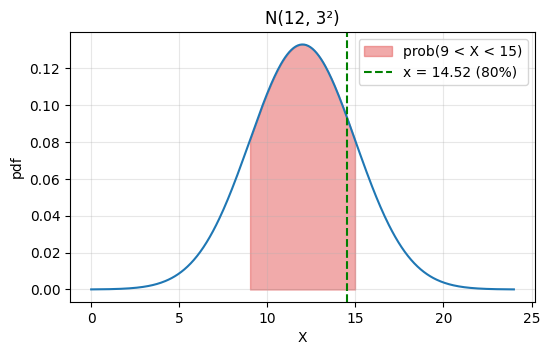

Cek vs manual (prob(X<15)): SAMA
Cek vs manual (prob(X<9)): SAMA
Cek vs manual (prob(9<X<15)): SAMA
Cek vs manual (x untuk 0.8, toleransi 0.001): SAMA


In [ ]:
mu, sigma = 12, 3
nor0_a = stats.norm.cdf(15, mu, sigma)             # Excel: NORM.DIST(15, 12, 3, TRUE)
nor0_b = stats.norm.cdf(9, mu, sigma)
nor0_c = nor0_a - nor0_b
nor0_x = stats.norm.ppf(0.8, mu, sigma)            # Excel: NORM.INV(0.8, 12, 3)
print(f"prob(X < 15) = {nor0_a:.4f} | prob(X < 9) = {nor0_b:.4f} | prob(9 < X < 15) = {nor0_c:.4f}")
print(f"x untuk prob(X < x) = 0.8 : {nor0_x:.4f}")

x = np.linspace(0, 24, 400)
y = stats.norm.pdf(x, mu, sigma)
plt.plot(x, y)
plt.fill_between(x, y, where=(x >= 9) & (x <= 15), color="#E45756", alpha=0.5, label="prob(9 < X < 15)")
plt.axvline(nor0_x, color="green", ls="--", label=f"x = {nor0_x:.2f} (80%)")
plt.xlabel("X"); plt.ylabel("pdf"); plt.legend(); plt.title("N(12, 3²)")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (prob(X<15)):", cocok(0.8413, nor0_a, 0.0001))
print("Cek vs manual (prob(X<9)):", cocok(0.1587, nor0_b, 0.0001))
print("Cek vs manual (prob(9<X<15)):", cocok(0.6827, nor0_c, 0.0001))
print("Cek vs manual (x untuk 0.8, toleransi 0.001):", cocok(14.5249, nor0_x, 0.001))

**Interpretasi NOR0:** prob(X < 15) = 0,8413 berarti 84,1% nilai X berada di bawah 15 (satu simpangan baku di atas rerata). Peluang X berada dalam ±1 simpangan baku (9 sampai 15) adalah 0,6827, sesuai aturan 68%. Persentil ke-80 adalah 14,5249: 80% nilai X berada di bawahnya. Fungsi `cdf` dan `ppf` adalah padanan NORM.DIST dan NORM.INV pada Excel.

#### Soal NOR1 — Nilai ujian di atas 85

**Soal:** Nilai ujian ~ N(70, 10²). Berapa peluang seorang mahasiswa mendapat nilai di atas 85?

**Hitungan manual:**

Z = (85−70)/10 = 1,5. P(X > 85) = 1 − Φ(1,5) = 1 − 0,93319 = 0,06681

Z = 1.5 | P(X > 85) = 0.06681
Manual vs Python: SAMA


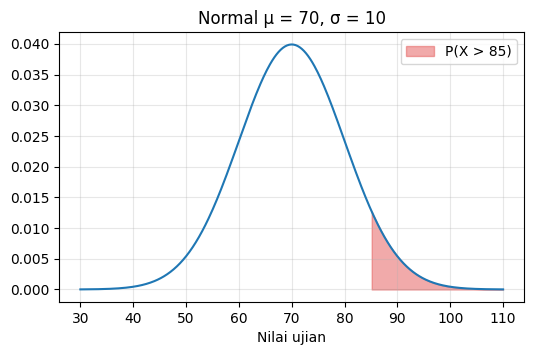

In [ ]:
mu, sigma = 70, 10
nor1_z = (85 - mu) / sigma
nor1_p = stats.norm.sf(85, mu, sigma)
print(f"Z = {nor1_z} | P(X > 85) = {nor1_p:.5f}")
print("Manual vs Python:", cocok(0.06681, nor1_p, 1e-5))

x = np.linspace(30, 110, 400)
y = stats.norm.pdf(x, mu, sigma)
plt.plot(x, y)
plt.fill_between(x, y, where=x >= 85, color="#E45756", alpha=0.5, label="P(X > 85)")
plt.xlabel("Nilai ujian"); plt.legend(); plt.title("Normal μ = 70, σ = 10")
plt.show()

**Interpretasi NOR1:** Nilai 85 berada 1,5 simpangan baku di atas rata-rata; hanya sekitar 6,7% mahasiswa yang mendapat nilai lebih tinggi. Daerah merah menggambarkan luas ekor kanan.

---
## Distribusi 7 — Eksponensial (kontinu)
X = waktu tunggu sampai kejadian berikutnya, laju λ (rata-rata 1/λ). f(x) = λe⁻λˣ (x ≥ 0)
P(X > x) = e⁻λˣ  |  E[X] = 1/λ  |  Var = 1/λ²  |  Median = ln 2 / λ
Fungsi: `stats.expon.pdf(x, scale=1/λ)` (scipy memakai `scale = 1/λ`), `.cdf`, `.sf`, `.ppf`, `.rvs`.

#### Soal EKS1 — Selang antar request

**Soal:** Selang waktu antar request ~ Eksponensial dengan rata-rata 2 menit (λ = 0,5/menit). Berapa peluang menunggu lebih dari 3 menit?

**Hitungan manual:**

P(X > 3) = e⁻⁰·⁵ˣ³ = e⁻¹·⁵ = 0,22313

P(X > 3) = 0.22313
Manual vs Python: SAMA


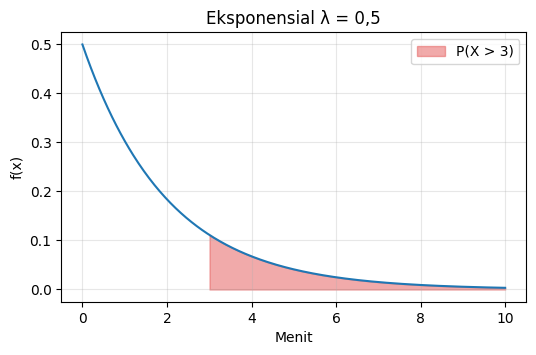

In [ ]:
lam = 0.5
E = stats.expon(scale=1 / lam)
eks1_p = E.sf(3)
print(f"P(X > 3) = {eks1_p:.5f}")
print("Manual vs Python:", cocok(math.exp(-1.5), eks1_p, 1e-9))

x = np.linspace(0, 10, 400)
plt.plot(x, E.pdf(x))
plt.fill_between(x, E.pdf(x), where=x >= 3, color="#E45756", alpha=0.5, label="P(X > 3)")
plt.xlabel("Menit"); plt.ylabel("f(x)"); plt.legend(); plt.title("Eksponensial λ = 0,5")
plt.show()

**Interpretasi EKS1:** Peluang menunggu lebih dari 3 menit adalah 0,2231 (≈ 22,3%). Kurva menurun tajam: selang pendek paling sering terjadi, selang panjang jarang namun tetap mungkin.

#### Soal EKS2 — Request datang dalam 1 menit

**Soal:** Pada kasus EKS1, berapa peluang request berikutnya datang dalam 1 menit?

**Hitungan manual:**

P(X ≤ 1) = 1 − e⁻⁰·⁵ = 1 − 0,60653 = 0,39347

In [ ]:
eks2_p = stats.expon.cdf(1, scale=2)
print(f"P(X <= 1) = {eks2_p:.5f}")
print("Manual vs Python:", cocok(1 - math.exp(-0.5), eks2_p, 1e-9))

P(X <= 1) = 0.39347
Manual vs Python: SAMA


**Interpretasi EKS2:** Ada 39,3% peluang request berikutnya datang dalam satu menit. Ingat bahwa parameter `scale` pada scipy adalah 1/λ = 2 (rata-rata), bukan λ.

#### Soal EKS6 — Hubungan Eksponensial dan Poisson

**Soal:** Request tiba dengan selang eksponensial (λ = 4 per menit), berarti jumlah request tiap menit berdistribusi Poisson(4). Buktikan dengan simulasi 20.000 menit dan bandingkan dengan P(X = 4) Poisson.

**Hitungan manual:**

Poisson(4): P(X=4) = e⁻⁴ 4⁴/4! = 0,19537; E = Var = 4

Jumlah request per menit: mean = 3.994, var = 4.020
P(X=4): simulasi = 0.1983 | Poisson = 0.1954


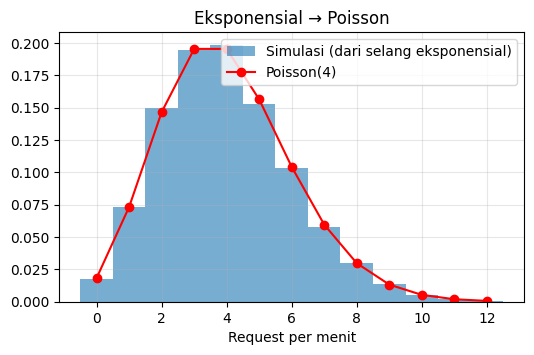

Cek vs manual (mean, toleransi 0.1): SAMA
Cek vs manual (var, toleransi 0.1): SAMA
Cek vs manual (P(X=4) Poisson): SAMA
Cek vs manual (P(X=4) simulasi, toleransi 0.01): SAMA


In [ ]:
lam = 4
menit = 20_000
selang = rng.exponential(1 / lam, size=int(menit * lam * 1.3))
waktu = np.cumsum(selang)
waktu = waktu[waktu < menit]
cacah = np.bincount(waktu.astype(int), minlength=menit)
eks6_mean, eks6_var = cacah.mean(), cacah.var()
eks6_p4 = np.mean(cacah == 4)
eks6_teori = stats.poisson.pmf(4, lam)
print(f"Jumlah request per menit: mean = {eks6_mean:.3f}, var = {eks6_var:.3f}")
print(f"P(X=4): simulasi = {eks6_p4:.4f} | Poisson = {eks6_teori:.4f}")

k = np.arange(0, 13)
plt.hist(cacah, bins=np.arange(-0.5, 13.5), density=True, alpha=0.6, label="Simulasi (dari selang eksponensial)")
plt.plot(k, stats.poisson.pmf(k, lam), "ro-", label="Poisson(4)")
plt.legend(); plt.xlabel("Request per menit"); plt.title("Eksponensial → Poisson")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (mean, toleransi 0.1):", cocok(4, eks6_mean, 0.1))
print("Cek vs manual (var, toleransi 0.1):", cocok(4, eks6_var, 0.1))
print("Cek vs manual (P(X=4) Poisson):", cocok(0.19537, eks6_teori, 1e-05))
print("Cek vs manual (P(X=4) simulasi, toleransi 0.01):", cocok(0.19537, eks6_p4, 0.01))

**Interpretasi EKS6:** Jumlah request tiap menit dari selang eksponensial memiliki mean 3,99 dan varians 4,02, ciri khas Poisson (mean = varians = 4). P(X=4) simulasi 0,1983 ≈ teori 0,1954. Jadi proses kedatangan Poisson dan selang waktu eksponensial adalah dua sisi dari model yang sama.

---
## Jembatan ke Statistika Deskriptif
Sampel acak dari sebuah distribusi dapat diringkas dengan alat statistika deskriptif (library `pandas`) dan dibaca memakai acuan pada lembar perkuliahan: mean vs median, kuartil dan IQR, simpangan baku, standard error, skewness, dan kurtosis. Di `pandas`, `Series.kurt()` memberi **excess kurtosis** (distribusi normal ≈ 0).

#### Soal DES1 — Ringkasan deskriptif sampel Normal

**Soal:** Bangkitkan 1.000 nilai ujian dari N(70, 10²). Susun ringkasan deskriptif (mean, median, min, max, Q1, Q3, IQR, varians, SD, SE, skewness, kurtosis, batas outlier) dan tafsirkan memakai acuan lembar perkuliahan.

**Hitungan manual:**

Teori: mean = 70, SD = 10, SE = σ/√n = 10/√1000 = 0,3162, skewness = 0, excess kurtosis = 0.
Batas outlier = Q1 − 1,5 IQR dan Q3 + 1,5 IQR (untuk normal sekitar 70 ± 2,7 × 10).

n                      1000.0000
mean                     69.9254
median (Q2)              70.2708
min                      40.7878
max                      97.1853
Q1                       63.1973
Q3                       76.7372
IQR                      13.5399
variance                 98.0318
std                       9.9011
SE (sem)                  0.3131
skewness                 -0.1445
excess kurtosis          -0.1531
batas bawah outlier      42.8874
batas atas outlier       97.0471
calon outlier             5.0000


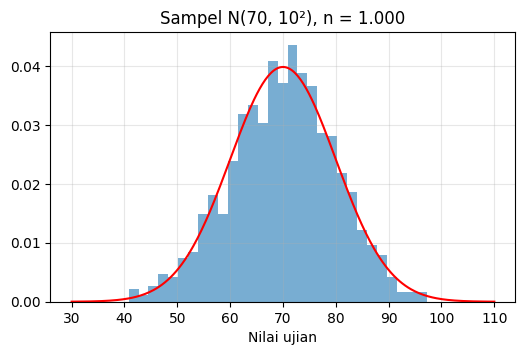

Cek vs manual (mean, toleransi 1.0): SAMA
Cek vs manual (SD, toleransi 0.5): SAMA
Cek vs manual (SE, toleransi 0.05): SAMA
Cek vs manual (skewness, toleransi 0.2): SAMA
Cek vs manual (excess kurtosis, toleransi 0.4): SAMA


In [ ]:
def ringkas_desk(s):
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"n": len(s), "mean": s.mean(), "median (Q2)": q2, "min": s.min(), "max": s.max(),
                      "Q1": q1, "Q3": q3, "IQR": iqr, "variance": s.var(), "std": s.std(), "SE (sem)": s.sem(),
                      "skewness": s.skew(), "excess kurtosis": s.kurt(),
                      "batas bawah outlier": bawah, "batas atas outlier": atas,
                      "calon outlier": int(((s < bawah) | (s > atas)).sum())})

nilai_ujian = pd.Series(rng.normal(70, 10, 1000))
des1 = ringkas_desk(nilai_ujian)
print(des1.round(4).to_string())
des1_mean, des1_sd, des1_se = des1["mean"], des1["std"], des1["SE (sem)"]
des1_skew, des1_kurt = des1["skewness"], des1["excess kurtosis"]
des1_selisih = abs(des1["mean"] - des1["median (Q2)"])

plt.hist(nilai_ujian, bins=30, density=True, alpha=0.6)
xx = np.linspace(30, 110, 300)
plt.plot(xx, stats.norm.pdf(xx, 70, 10), "r")
plt.xlabel("Nilai ujian"); plt.title("Sampel N(70, 10²), n = 1.000")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (mean, toleransi 1.0):", cocok(70, des1_mean, 1.0))
print("Cek vs manual (SD, toleransi 0.5):", cocok(10, des1_sd, 0.5))
print("Cek vs manual (SE, toleransi 0.05):", cocok(10/math.sqrt(1000), des1_se, 0.05))
print("Cek vs manual (skewness, toleransi 0.2):", cocok(0, des1_skew, 0.2))
print("Cek vs manual (excess kurtosis, toleransi 0.4):", cocok(0, des1_kurt, 0.4))

**Interpretasi DES1:** Mean 69,93 dan median berselisih hanya 0,35 (jauh di bawah 2–3% skala 0–100), skewness -0,144 berada dalam ±0,5 dan excess kurtosis -0,153 dekat 0; berdasarkan acuan lembar perkuliahan, sampel ini simetris dan mendekati normal. SD 9,90 berada tepat di sekitar batas 10 (acuan: SD < 10 sangat homogen, 10–15 variasi wajar), sesuai nilai teori 10. SE = 0,313, sangat kecil terhadap SD, jadi rata-rata sampel menaksir rata-rata populasi dengan presisi tinggi.

#### Soal DES2 — Ringkasan deskriptif sampel Eksponensial (data miring)

**Soal:** Bangkitkan 200.000 selang waktu antar request dari Eksponensial dengan rata-rata 2 detik. Bandingkan mean dan median, skewness, dan kurtosis dengan teori, lalu tafsirkan.

**Hitungan manual:**

Teori: mean = 2; median = 2 ln 2 = 1,3863; skewness = 2; excess kurtosis = 6.
Mean > median → distribusi miring ke kanan (positive skewness).

n                      200000.0000
mean                        2.0002
median (Q2)                 1.3886
min                         0.0000
max                        29.1713
Q1                          0.5770
Q3                          2.7738
IQR                         2.1967
variance                    3.9868
std                         1.9967
SE (sem)                    0.0045
skewness                    1.9893
excess kurtosis             5.9707
batas bawah outlier        -2.7181
batas atas outlier          6.0689
calon outlier            9678.0000
Proporsi calon outlier = 4.84%


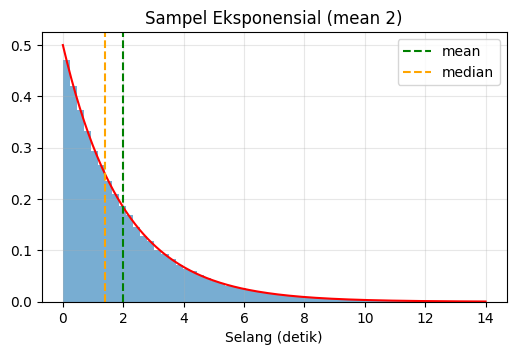

Cek vs manual (mean, toleransi 0.05): SAMA
Cek vs manual (median, toleransi 0.05): SAMA
Cek vs manual (skewness, toleransi 0.3): SAMA
Cek vs manual (excess kurtosis, toleransi 1.5): SAMA


In [ ]:
selang = pd.Series(rng.exponential(2, 200_000))
des2 = ringkas_desk(selang)
print(des2.round(4).to_string())
des2_mean, des2_med = des2["mean"], des2["median (Q2)"]
des2_skew, des2_kurt = des2["skewness"], des2["excess kurtosis"]
des2_outlier = des2["calon outlier"] / des2["n"]
print(f"Proporsi calon outlier = {des2_outlier:.2%}")

plt.hist(selang, bins=60, range=(0, 14), density=True, alpha=0.6)
xx = np.linspace(0, 14, 300)
plt.plot(xx, stats.expon.pdf(xx, scale=2), "r")
plt.axvline(des2_mean, color="green", ls="--", label="mean"); plt.axvline(des2_med, color="orange", ls="--", label="median")
plt.legend(); plt.xlabel("Selang (detik)"); plt.title("Sampel Eksponensial (mean 2)")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (mean, toleransi 0.05):", cocok(2, des2_mean, 0.05))
print("Cek vs manual (median, toleransi 0.05):", cocok(2*math.log(2), des2_med, 0.05))
print("Cek vs manual (skewness, toleransi 0.3):", cocok(2, des2_skew, 0.3))
print("Cek vs manual (excess kurtosis, toleransi 1.5):", cocok(6, des2_kurt, 1.5))

**Interpretasi DES2:** Mean 2,000 lebih besar dari median 1,389, dan skewness 1,99 (teori tepat 2) berada di batas antara 'dapat ditoleransi' dan 'kemencengan kuat' menurut acuan, dengan ekor panjang di kanan, sedangkan excess kurtosis 5,97 jauh di atas +2 (leptokurtik: runcing dan berekor berat). Tidak seperti sampel normal, 4,8% data tergolong calon outlier. Pada data seperti ini median lebih mewakili nilai tipikal daripada mean.

---
## Ringkasan Seluruh Distribusi
Selain E[X] dan Var(X), tabel memuat median, skewness, dan excess kurtosis. Acuan skewness dari lembar perkuliahan: |cs| ≤ 0,5 sangat mendekati simetris; ≤ 1 cukup dekat simetris; ≤ 2 dapat ditoleransi; > 2 kemencengan kuat. Pada distribusi miring kanan (positif), mean > median.

In [ ]:
def tafsir(sk):
    a = abs(sk)
    kat = "sangat mendekati simetris" if a <= 0.5 else "cukup dekat simetris" if a <= 1 else "dapat ditoleransi" if a <= 2 else "kemencengan kuat"
    return kat + (" (ekor kanan)" if sk > 0.05 else " (ekor kiri)" if sk < -0.05 else "")

daftar = [
    ("Hipergeometrik (N=50, k=8, n=5)", "diskrit", stats.hypergeom(50, 8, 5)),
    ("Binomial (n=10, p=0,3)",          "diskrit", stats.binom(10, .3)),
    ("Poisson (λ=4)",                   "diskrit", stats.poisson(4)),
    ("Geometrik (p=0,2)",               "diskrit", stats.geom(.2)),
    ("Binomial Negatif (r=3, p=0,6)",   "diskrit", stats.nbinom(3, .6, loc=3)),
    ("Normal (70; 10²)",                "kontinu", stats.norm(70, 10)),
    ("Eksponensial (mean 2)",           "kontinu", stats.expon(scale=2)),
]
baris = []
for nama, jenis, d in daftar:
    m, v, sk, ku = d.stats(moments="mvsk")
    baris.append([nama, jenis, float(m), float(d.median()), float(v), float(sk), float(ku), tafsir(float(sk))])
ringkas = pd.DataFrame(baris, columns=["Distribusi", "Jenis", "E[X]", "Median", "Var(X)", "Skewness", "Excess kurtosis", "Bentuk (acuan skewness)"])
print(ringkas.round(4).to_string(index=False))
ringkas_eks_skew = float(stats.expon(scale=2).stats(moments="s"))

                     Distribusi   Jenis  E[X]  Median   Var(X)  Skewness  Excess kurtosis                Bentuk (acuan skewness)
Hipergeometrik (N=50, k=8, n=5) diskrit   0.8  1.0000   0.6171    0.7213           0.0628      cukup dekat simetris (ekor kanan)
         Binomial (n=10, p=0,3) diskrit   3.0  3.0000   2.1000    0.2760          -0.1238 sangat mendekati simetris (ekor kanan)
                  Poisson (λ=4) diskrit   4.0  4.0000   4.0000    0.5000           0.2500 sangat mendekati simetris (ekor kanan)
              Geometrik (p=0,2) diskrit   5.0  4.0000  20.0000    2.0125           6.0500          kemencengan kuat (ekor kanan)
  Binomial Negatif (r=3, p=0,6) diskrit   5.0  5.0000   3.3333    1.2780           2.3000         dapat ditoleransi (ekor kanan)
               Normal (70; 10²) kontinu  70.0 70.0000 100.0000    0.0000           0.0000              sangat mendekati simetris
          Eksponensial (mean 2) kontinu   2.0  1.3863   4.0000    2.0000           6.0000        

## Kesimpulan Umum
1. **Diskrit** memakai `pmf` (peluang titik) sedangkan **kontinu** memakai `pdf` (kepadatan) dan peluang dihitung sebagai selisih `cdf`; peluang di satu titik pada distribusi kontinu bernilai 0.
2. `cdf`, `sf` (=1−cdf), dan `ppf` (invers cdf) adalah tiga fungsi yang paling banyak dipakai untuk menjawab pertanyaan 'paling banyak', 'lebih dari', dan 'batas nilai untuk persentil tertentu'.
3. Hasil hitungan manual selalu cocok dengan `scipy.stats`, dan simulasi (`rvs`) mendekati teori ketika jumlah sampel besar.
4. Hubungan antar distribusi terkonfirmasi: Poisson ≈ Binomial (n besar, p kecil), Binomial ≈ Normal (CLT), Hipergeometrik ≈ Binomial (populasi besar), Eksponensial ↔ Poisson.
5. Sifat khusus: Geometrik dan Eksponensial **tanpa ingatan** (memoryless); Poisson memiliki mean = varians; hipergeometrik memiliki varians lebih kecil karena pengambilan tanpa pengembalian.